# 12 同時購入の店舗・月別構成を考慮した探索

商品の同時購入は販売期間・店舗構成の違いだけでも関連して見える。全会計を一括で比較した lift と、**店舗×年×月** ごとに独立を仮定した期待共起数を合計して作った比を比較する。

調整後でも曜日・キャンペーン・客層・同月中の販売期間やセット販売は揃っていない。因果効果・推薦施策の評価ではない。稀な商品ペアは比率が不安定なので期待件数・実測件数を表示する。

In [1]:
from pathlib import Path
import zipfile,io
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir(): ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.options.display.float_format='{:,.4f}'.format
menus=pd.read_csv(INPUT/'menus.csv').sort_values('item_id').reset_index(drop=True)
items=menus.item_id.tolist(); index={x:i for i,x in enumerate(items)}
stores=pd.read_csv(INPUT/'stores.csv').store_id.tolist();n=len(items)
observed=np.zeros((n,n),dtype=np.int64); expected_stratified=np.zeros((n,n),dtype=float)
total_orders=0; strata_info=[]

## 店舗・年・月ごとに全会計を処理
各層の期待件数は `count(A) × count(B) / 会計数`。層ごとの実測共起数と期待件数を合計して比を求める。同一会計での商品重複は1回として扱う。

In [2]:
with zipfile.ZipFile(INPUT/'logs.zip') as z:
    for sid in stores:
        with z.open(f'logs/{sid}/order_items.parquet') as f:
            order=pq.read_table(io.BytesIO(f.read()),columns=['order_id','date','item_id']).to_pandas()
        assert order.order_id.notna().all() and order.item_id.isin(items).all()
        order['year']=order.date.dt.year;order['month']=order.date.dt.month
        for (year,month),frame in order.groupby(['year','month'],observed=True):
            row,unique=pd.factorize(frame.order_id,sort=False)
            col=frame.item_id.map(index).to_numpy(dtype=np.int64)
            X=coo_matrix((np.ones(len(frame),dtype=np.int64),(row,col)),shape=(len(unique),n)).tocsr();X.data[:]=1
            counts=(X.T@X).toarray();frequency=np.diag(counts)
            observed+=counts;expected_stratified+=np.outer(frequency,frequency)/len(unique);total_orders+=len(unique)
            strata_info.append({'store_id':sid,'year':int(year),'month':int(month),'orders':len(unique),'lines':len(frame)})
        print(sid,'全注文行:',len(order),'完了',flush=True)
        del order,X
strata=pd.DataFrame(strata_info)
print('店舗×年×月の層:',len(strata),'全会計数:',total_orders,'全注文明細行:',strata.lines.sum())
assert len(strata)==360 and total_orders==2337482 and int(strata.lines.sum())==8417590
assert np.array_equal(observed,observed.T)
display(strata.groupby('year')[['orders','lines']].sum())

S001 全注文行: 1006670 完了
S002 全注文行: 866515 完了
S003 全注文行: 964313 完了
S004 全注文行: 1112487 完了
S005 全注文行: 801335 完了
S006 全注文行: 596023 完了
S007 全注文行: 731885 完了
S008 全注文行: 684457 完了
S009 全注文行: 579569 完了
S010 全注文行: 1074336 完了
店舗×年×月の層: 360 全会計数: 2337482 全注文明細行: 8417590


,orders,lines
year,,
2022,744000,2697160
2023,791833,2843065
2024,801649,2877365


## 一括 lift と店舗・月調整後の比
調整後の比 = 全層の共起実績合計 ÷ 各層の独立仮定による期待共起数の合計。一括 lift と同様に1より大きいと期待より共起が多いが、条件付きの因果効果ではない。

In [3]:
frequencies=np.diag(observed);records=[]
for i in range(n):
    for j in range(i+1,n):
        count=int(observed[i,j]);expected=float(expected_stratified[i,j]);global_expected=float(frequencies[i]*frequencies[j]/total_orders)
        if count==0 or expected==0 or global_expected==0: continue
        records.append({'item_a':items[i],'item_b':items[j],'count':count,'global_expected':global_expected,'stratified_expected':expected,'global_lift':count/global_expected,'store_month_ratio':count/expected})
pairs=pd.DataFrame(records)
info=menus[['item_id','item_name','category','menu_type']]
pairs=(pairs.merge(info.rename(columns={'item_id':'item_a','item_name':'name_a','category':'category_a','menu_type':'type_a'}),on='item_a',validate='many_to_one')
       .merge(info.rename(columns={'item_id':'item_b','item_name':'name_b','category':'category_b','menu_type':'type_b'}),on='item_b',validate='many_to_one'))
pairs['change_in_ratio']=pairs.store_month_ratio-pairs.global_lift
cols=['item_a','name_a','item_b','name_b','count','global_expected','stratified_expected','global_lift','store_month_ratio']
reliable=pairs[(pairs['count']>=1000)&(pairs.stratified_expected>=100)].copy()
print('比較対象ペア（実測1000件・期待100件以上）:',len(reliable))
print('調整前後の差が大きいペア:');display(reliable.nsmallest(20,'change_in_ratio')[cols])
print('店舗・月調整後の比が高いペア:');display(reliable.nlargest(20,'store_month_ratio')[cols])

比較対象ペア（実測1000件・期待100件以上）: 2206
調整前後の差が大きいペア:
店舗・月調整後の比が高いペア:


,item_a,name_a,item_b,name_b,count,global_expected,stratified_expected,global_lift,store_month_ratio
3280,M082,Anime Hero Fire Burger,M084,Anime Hero Side Star Plate,2402,83.9652,"1,151.6300",28.6071,2.0857
3279,M082,Anime Hero Fire Burger,M083,Anime Hero Prism Parfait,1120,48.5779,659.4655,23.0558,1.6983
3211,M067,Mango Coconut Parfait,M069,Salt Lemon Chicken Basket,2120,331.2940,"1,418.2624",6.3991,1.4948
3200,M066,Spicy Tex Mex Burger Plate,M069,Salt Lemon Chicken Basket,7455,"1,291.8558","5,277.8793",5.7708,1.4125
3221,M068,Chilled Tomato Pasta,M069,Salt Lemon Chicken Basket,6782,"1,232.2370","5,028.0094",5.5038,1.3488
3251,M071,Mont Blanc Pancake,M072,Pumpkin Cream Doria,2881,578.4046,"2,460.8251",4.9809,1.1707
3168,M063,Spring Herb Chicken Plate,M064,Berry Parfait Tower,3055,614.4182,"2,545.1547",4.9722,1.2003
3198,M066,Spicy Tex Mex Burger Plate,M067,Mango Coconut Parfait,4011,809.8403,"3,308.5561",4.9528,1.2123
3149,M061,Strawberry Chocolate Pancake,M062,White Stew Pot Pie,3272,677.1312,"2,803.5207",4.8322,1.1671
3240,M070,Autumn Mushroom Hamburg,M071,Mont Blanc Pancake,2789,588.3827,"2,483.7219",4.7401,1.1229


,item_a,name_a,item_b,name_b,count,global_expected,stratified_expected,global_lift,store_month_ratio
20,M001,Drink Bar (Single),M056,Coffee Jelly,3724,651.6764,666.5296,5.7145,5.5871
23,M001,Drink Bar (Single),M059,Tiramisu Cup,3843,686.5796,702.9461,5.5973,5.4670
22,M001,Drink Bar (Single),M058,Cream Anmitsu,3487,627.4278,643.2100,5.5576,5.4212
14,M001,Drink Bar (Single),M050,Cheese Cake,3844,692.8734,709.9091,5.5479,5.4148
17,M001,Drink Bar (Single),M053,Custard Pudding,3533,641.0856,656.0350,5.5110,5.3854
18,M001,Drink Bar (Single),M054,Mont Blanc,4013,728.3517,747.8497,5.5097,5.3661
21,M001,Drink Bar (Single),M057,Hot Apple Pie,3913,721.1474,739.6625,5.4261,5.2903
15,M001,Drink Bar (Single),M051,Chocolate Sundae,4058,755.7152,776.2682,5.3697,5.2276
28,M001,Drink Bar (Single),M071,Mont Blanc Pancake,1509,281.3985,289.6937,5.3625,5.2089
24,M001,Drink Bar (Single),M061,Strawberry Chocolate Pancake,1604,296.9731,309.3707,5.4012,5.1847


## 商品種類の組み合わせ別の傾向
各点は商品ペア。横軸・縦軸はいずれも対数スケール。点ごとの共起は会計を共有するため独立な観測ではない。

,pairs,global_median,store_month_median,observed_pairs
type_pair,,,,
collaboration × collaboration,2,25.8314,1.8920,3522
collaboration × core,64,1.0818,1.0599,157598
collaboration × seasonal,2,1.5300,0.8454,2481
core × core,1584,1.1532,1.1410,11945309
core × seasonal,539,1.1716,1.1422,2304032
seasonal × seasonal,15,4.7401,1.1485,79129


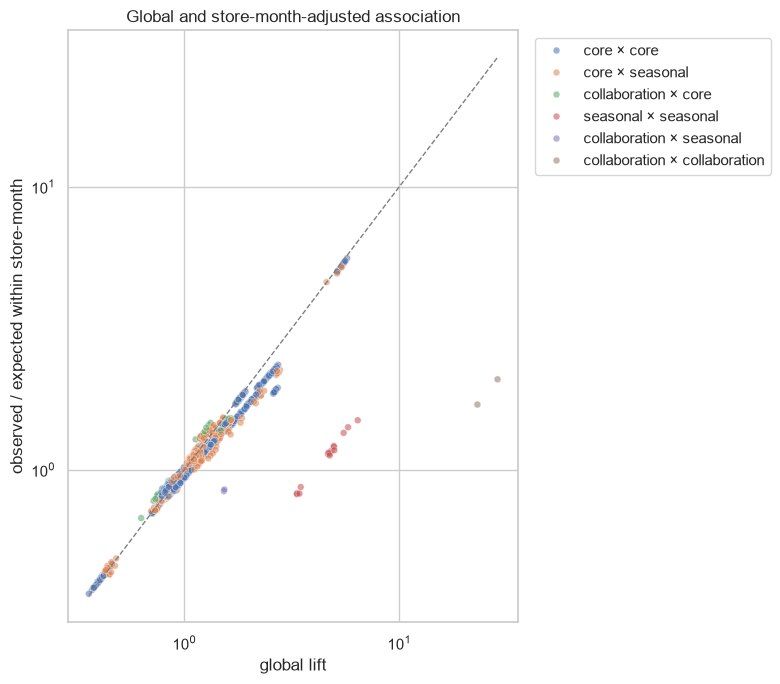

In [4]:
reliable['type_pair']=reliable.apply(lambda r:' × '.join(sorted([r.type_a,r.type_b])),axis=1)
display(reliable.groupby('type_pair').agg(pairs=('item_a','size'),global_median=('global_lift','median'),store_month_median=('store_month_ratio','median'),observed_pairs=('count','sum')))
fig,ax=plt.subplots(figsize=(8,7));sns.scatterplot(data=reliable,x='global_lift',y='store_month_ratio',hue='type_pair',alpha=.55,s=24,ax=ax)
limits=[min(reliable.global_lift.min(),reliable.store_month_ratio.min()),max(reliable.global_lift.max(),reliable.store_month_ratio.max())]
ax.plot(limits,limits,color='gray',lw=1,ls='--');ax.set_xscale('log');ax.set_yscale('log');ax.set(title='Global and store-month-adjusted association',xlabel='global lift',ylabel='observed / expected within store-month');ax.legend(bbox_to_anchor=(1.02,1),loc='upper left');plt.tight_layout();plt.show()

## 解釈
- 店舗・月調整後も、共通の販売日、キャンペーン、曜日、客層やセット販売が共起を生む。
- 会計数や期待共起数の小さなペアは不安定。上の閾値は可視化のための任意の条件であり、有意性の保証ではない。
- 2025年の同日販売実績は未観測。過去から作った統計を用いる場合も、検証基準日より前の期間に限定する。